In [1]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)

# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'1': 661, '0': 363}


In [2]:
sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

Basis gates used: OrderedDict({'x': 1, 'measure': 1})


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

All imports OK ✅


In [4]:
p_true = 0.3

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

Problem defined ✅


In [12]:
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# Build noise model
noise_model_test = NoiseModel()
error_1q = depolarizing_error(0.75, 1)
noise_model_test.add_all_qubit_quantum_error(
    error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# ── Clean baseline ──
sampler_clean = AerSampler(
    run_options={"shots": 1024}         # shots in run_options
)
iae_clean = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_clean
)
result_clean = iae_clean.estimate(problem)
print(f"p=0.00 | Estimate: {result_clean.estimation:.4f} | Queries: {result_clean.num_oracle_queries}")

# ── Noisy run ──
sampler_noisy = AerSampler(
    backend_options={"noise_model": noise_model_test},  # ✅ noise in backend_options
    run_options={"shots": 1024}                         # ✅ shots in run_options
)
iae_noisy = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_noisy
)
result_noisy = iae_noisy.estimate(problem)
print(f"p=0.75 | Estimate: {result_noisy.estimation:.4f} | Queries: {result_noisy.num_oracle_queries}")

# ── Difference check ──
diff = abs(result_clean.estimation - result_noisy.estimation)
print(f"\nDifference: {diff:.4f}")
if diff < 0.01:
    print("❌ Noise is NOT being applied!")
else:
    print("✅ Noise IS affecting the estimate!")

p=0.00 | Estimate: 0.3017 | Queries: 7168
p=0.75 | Estimate: 0.4922 | Queries: 3072

Difference: 0.1905
✅ Noise IS affecting the estimate!


In [14]:
import numpy as np
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS — all defined here, nothing external
# ══════════════════════════════════════════════
N_REPEATS      = 30
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 40).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.6, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": 1024}
        )
    else:
        sampler = AerSampler(run_options={"shots": 1024})
    return sampler

# ══════════════════════════════════════════════
# SWEEP
# ══════════════════════════════════════════════
sweep_results = []
run_count     = 0

for p_noise in noise_levels:
    print(f"\n--- Noise p = {p_noise:.5f} ---")
    sampler = build_noisy_sampler(p_noise)

    for eps in epsilon_values:
        estimates = []
        queries   = []

        for repeat in range(N_REPEATS):
            run_count += 1
            try:
                iae = IterativeAmplitudeEstimation(
                    epsilon_target=eps,
                    alpha=0.05,
                    sampler=sampler,
                )
                result = iae.estimate(problem)
                estimates.append(result.estimation)
                queries.append(result.num_oracle_queries)
            except Exception as e:
                estimates.append(0.0)
                queries.append(0)

        estimates   = np.array(estimates)
        rmse        = np.sqrt(np.mean((estimates - p_true) ** 2))
        avg_queries = np.mean(queries)
        collapsed   = rmse > eps

        individual_success = [
            1 if abs(est - p_true) <= eps else 0
            for est in estimates
        ]
        success_rate = np.mean(individual_success)

        sweep_results.append({
            "epsilon"     : eps,
            "noise"       : p_noise,
            "queries"     : avg_queries,
            "rmse"        : rmse,
            "collapsed"   : collapsed,
            "success_rate": success_rate,
        })

        print(f"  [Run {run_count}/{total_runs}] "
              f"eps={eps:.6f} | "
              f"Queries={avg_queries:>8.1f} | "
              f"RMSE={rmse:.5f} | "
              f"Success={success_rate:.2f} | "
              f"{'💀 FAILED' if collapsed else '✅ OK'}")

print(f"\n✅ Sweep complete — {total_runs} total runs")

Epsilon values    : 40 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.6000
Total combinations: 1640
Total IQAE runs   : 49200

--- Noise p = 0.00000 ---


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_7100\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 30/49200] eps=0.000100 | Queries=1506406.4 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 60/49200] eps=0.000119 | Queries=1637239.5 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 90/49200] eps=0.000143 | Queries=1570065.1 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 120/49200] eps=0.000170 | Queries=1469644.8 | RMSE=0.00311 | Success=0.97 | 💀 FAILED
  [Run 150/49200] eps=0.000203 | Queries=1085098.7 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 180/49200] eps=0.000242 | Queries=870263.5 | RMSE=0.00003 | Success=1.00 | ✅ OK
  [Run 210/49200] eps=0.000289 | Queries=490257.1 | RMSE=0.00005 | Success=1.00 | ✅ OK
  [Run 240/49200] eps=0.000346 | Queries=466432.0 | RMSE=0.00006 | Success=1.00 | ✅ OK


KeyboardInterrupt: 

Error in callback <function _enable_matplotlib_integration.<locals>.configure_once at 0x000001CA4DC99300> (for post_run_cell), with arguments args (<ExecutionResult object at 1ca4fb893d0, execution_count=14 error_before_exec=None error_in_exec= info=<ExecutionInfo object at 1ca4fb89cd0, raw_cell="import numpy as np
from qiskit_aer.primitives impo.." transformed_cell="import numpy as np
from qiskit_aer.primitives impo.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/c%3A/documents%20for%20me/Summer-Research-2026/IQAE%20%2B%20Noise.ipynb#W5sZmlsZQ%3D%3D> result=None>,),kwargs {}:


AttributeError: module 'matplotlib' has no attribute 'backends'

In [ ]:
import numpy as np
from joblib import Parallel, delayed
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════
N_REPEATS      = 10
N_JOBS         = 18  # leave 2 threads free for system
N_shots        = 16384
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": N_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": N_shots})
    return sampler

# ══════════════════════════════════════════════
# SINGLE COMBINATION FUNCTION — runs in parallel
# ══════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats):
    """
    Fully independent — safe to run in parallel.
    Each worker builds its own sampler.
    """
    sampler   = build_noisy_sampler(p_noise)
    estimates = []
    queries   = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target=eps,
                alpha=0.05,
                sampler=sampler,
            )
            result = iae.estimate(problem)
            estimates.append(result.estimation)
            queries.append(result.num_oracle_queries)
        except:
            estimates.append(0.0)
            queries.append(0)

    estimates    = np.array(estimates)
    rmse         = np.sqrt(np.mean((estimates - p_true) ** 2))
    avg_queries  = np.mean(queries)
    collapsed    = rmse > eps
    success_rate = np.mean([
        1 if abs(est - p_true) <= eps else 0
        for est in estimates
    ])

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "queries"     : avg_queries,
        "rmse"        : rmse,
        "collapsed"   : collapsed,
        "success_rate": success_rate,
    }

# ══════════════════════════════════════════════
# BUILD ALL COMBINATIONS
# ══════════════════════════════════════════════
combinations = [
    (p_noise, eps)
    for p_noise in noise_levels
    for eps in epsilon_values
]

print(f"\n🚀 Starting parallel sweep...")

# ══════════════════════════════════════════════
# RUN IN PARALLEL — verbose=10 shows progress
# ══════════════════════════════════════════════
sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
    delayed(run_combination)(p_noise, eps, p_true, N_REPEATS)
    for p_noise, eps in combinations
)

print(f"\n✅ Sweep complete — {len(sweep_results)} combinations done")

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.4000
Total combinations: 4100
Total IQAE runs   : 123000
Running on        : 18 parallel threads

🚀 Starting parallel sweep...


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   53.2s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   59.3s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:  1.8min
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:  2.0min
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:  2.6min
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  2.7min
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:  3.0min
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  3.3min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  3.5min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  3.9min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  


✅ Sweep complete — 4100 combinations done


[Parallel(n_jobs=18)]: Done 4100 out of 4100 | elapsed: 37.9min finished


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit
from joblib import Parallel, delayed
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
SHOT_VALUES    = [1024, 4096, 16384, 65536]
N_REPEATS      = 10
N_JOBS         = 18
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs} per shot count")
print(f"Shot values       : {SHOT_VALUES}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q        = min(p_depol, 0.75)
        error_1q    = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

# ══════════════════════════════════════════════════════════════════════════════
# SINGLE COMBINATION — runs in parallel
# ══════════════════════════════════════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats, n_shots):
    """
    Fully independent — safe to run in parallel.
    Each worker builds its own sampler with its own shot count.
    """
    sampler   = build_noisy_sampler(p_noise, n_shots)
    estimates = []
    queries   = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target=eps,
                alpha=0.05,
                sampler=sampler,
            )
            result = iae.estimate(problem)
            estimates.append(result.estimation)
            queries.append(result.num_oracle_queries)
        except:
            estimates.append(0.0)
            queries.append(0)

    estimates    = np.array(estimates)
    rmse_val     = np.sqrt(np.mean((estimates - p_true) ** 2))
    avg_queries  = np.mean(queries)
    collapsed    = rmse_val > eps
    success_rate = np.mean([
        1 if abs(est - p_true) <= eps else 0
        for est in estimates
    ])

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "queries"     : avg_queries,
        "rmse"        : rmse_val,
        "collapsed"   : collapsed,
        "success_rate": success_rate,
    }

# ══════════════════════════════════════════════════════════════════════════════
# CURVE FIT MODELS  —  x-axis is log10(epsilon)
#
#   Exponential Decay : p*(ε) = a · exp( b · log10(ε) )
#                             = a · ε^b          (power law in disguise)
#     Physical read   : every decade decrease in ε multiplies tolerance by e^b
#     Asymptote       : p* → 0  as  ε → 0  (b > 0)  ✅
#
#   Power-Epsilon     : p*(ε) = a · |log10(ε)|^(-b)
#     Physical read   : tolerance decays as a power of the log-precision
#     Asymptote       : p* → 0  as  ε → 0  (b > 0)  ✅
#
#   Both are fit on  x = log10(ε)  which is negative (ε < 1),
#   so we pass  log_eps = log10(epsilon)  directly.
# ══════════════════════════════════════════════════════════════════════════════
def model_exp_decay(log_eps, a, b):
    """
    p*(ε) = a · exp( b · log10(ε) )
    Fit variable : log_eps = log10(ε)   [negative for ε < 1]
    Parameters   : a > 0  (scale),  b > 0  (decay rate)
    Note         : mathematically identical to a · ε^b
    """
    return a * np.exp(b * log_eps)

def model_power_eps(log_eps, a, b):
    """
    p*(ε) = a · |log10(ε)|^(-b)
    Fit variable : log_eps = log10(ε)   [negative for ε < 1]
    Parameters   : a > 0  (scale),  b > 0  (decay rate)
    """
    return a * (np.abs(log_eps) ** (-b))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# BOUNDARY EXTRACTOR
#   For each unique epsilon, take the top-2 highest noise levels
#   where collapsed == False  →  these define the noise frontier
# ══════════════════════════════════════════════════════════════════════════════
def extract_boundary_points(sweep_results):
    """
    Returns arrays:
        eps_boundary  : epsilon values of boundary points
        noise_boundary: corresponding noise threshold values
    """
    eps_boundary   = []
    noise_boundary = []

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        # All working entries for this epsilon, sorted by noise descending
        working_noise = sorted(
            [e["noise"] for e in sweep_results
             if e["epsilon"] == eps and not e["collapsed"]],
            reverse=True
        )
        # Take top 2
        for p in working_noise[:2]:
            eps_boundary.append(eps)
            noise_boundary.append(p)

    return np.array(eps_boundary), np.array(noise_boundary)

# ══════════════════════════════════════════════════════════════════════════════
# FIT BOTH MODELS TO BOUNDARY POINTS
# ══════════════════════════════════════════════════════════════════════════════
def fit_models(eps_boundary, noise_boundary):
    """
    Fits both models on log10(epsilon) vs noise boundary points.
    Returns dict of results for each model.
    """
    log_eps = np.log10(eps_boundary)   # negative values, e.g. -4 → -1

    candidates = {
        "Exponential Decay  [a·exp(b·log(ε))]": {
            "func"  : model_exp_decay,
            "p0"    : [0.5,  1.0],
            "bounds": ([0.0,  0.001], [np.inf, np.inf]),
            "tex"   : r"$p^*(\varepsilon)=a\cdot e^{b\log_{10}\varepsilon}$",
            "color" : "#e67e22",
        },
        "Power-Epsilon       [a·|log(ε)|^(-b)]": {
            "func"  : model_power_eps,
            "p0"    : [0.5,  1.0],
            "bounds": ([0.0,  0.001], [np.inf, np.inf]),
            "tex"   : r"$p^*(\varepsilon)=a\cdot|\log_{10}\varepsilon|^{-b}$",
            "color" : "#3498db",
        },
    }

    results = {}
    for label, cfg in candidates.items():
        try:
            popt, pcov = curve_fit(
                cfg["func"],
                log_eps,
                noise_boundary,
                p0     = cfg["p0"],
                bounds = cfg["bounds"],
                maxfev = 20_000
            )
            perr   = np.sqrt(np.diag(pcov))
            y_pred = cfg["func"](log_eps, *popt)
            r2     = r_squared(noise_boundary, y_pred)
            rm     = rmse_metric(noise_boundary, y_pred)

            results[label] = {
                "popt" : popt,
                "perr" : perr,
                "r2"   : r2,
                "rmse" : rm,
                "func" : cfg["func"],
                "tex"  : cfg["tex"],
                "color": cfg["color"],
            }
        except RuntimeError as exc:
            results[label] = None
            print(f"   ⚠ Fit failed for {label}: {exc}")

    return results

# ══════════════════════════════════════════════════════════════════════════════
# PRINT RESULTS FOR ONE SHOTS COUNT
# ══════════════════════════════════════════════════════════════════════════════
def print_shot_results(n_shots, fit_results):
    print(f"\n{'═'*75}")
    print(f"  SHOTS = {n_shots}")
    print(f"{'═'*75}")
    print(f"  {'Model':<42} {'R²':>8} {'RMSE':>10} {'a':>10} {'b':>10}")
    print(f"  {'-'*72}")
    for label, res in fit_results.items():
        if res is None:
            print(f"  {label:<42} {'—':>8} {'—':>10} {'—':>10} {'—':>10}  ❌ Failed")
            continue
        a, b = res["popt"]
        print(
            f"  {label:<42} "
            f"{res['r2']:>8.4f} "
            f"{res['rmse']:>10.6f} "
            f"{a:>10.6f} "
            f"{b:>10.6f}"
        )
    print(f"{'═'*75}")

# ══════════════════════════════════════════════════════════════════════════════
# PLOT FOR ONE SHOTS COUNT
# ══════════════════════════════════════════════════════════════════════════════
def plot_shot_results(n_shots, sweep_results, fit_results, eps_boundary, noise_boundary):
    fig, ax = plt.subplots(figsize=(12, 7))

    noise_all = np.array([e["noise"] for e in sweep_results])

    # — All scatter points
    for entry in sweep_results:
        color  = '#2ecc71' if not entry["collapsed"] else '#e74c3c'
        marker = 'o'       if not entry["collapsed"] else 'X'
        ax.scatter(
            np.log10(entry["epsilon"]), entry["noise"],
            color=color, marker=marker, s=60,
            zorder=5, edgecolors='black', linewidths=0.3, alpha=0.75
        )

    # — Boundary points (top-2 per epsilon)
    ax.scatter(
        np.log10(eps_boundary), noise_boundary,
        color='white', edgecolors='gold',
        linewidths=1.8, s=80, zorder=13,
        label='Boundary points (top-2 per ε)'
    )

    # — Dense x for smooth curves
    log_eps_dense = np.linspace(
        np.log10(min(epsilon_values)),
        np.log10(max(epsilon_values)),
        600
    )

    best_label = max(
        [k for k, v in fit_results.items() if v is not None],
        key=lambda k: fit_results[k]["r2"]
    )

    for label, res in fit_results.items():
        if res is None:
            continue
        y_dense  = np.clip(res["func"](log_eps_dense, *res["popt"]), 0, noise_all.max())
        is_best  = (label == best_label)
        ax.plot(
            log_eps_dense, y_dense,
            color    = res["color"],
            linewidth= 3.0 if is_best else 1.6,
            linestyle= '--' if is_best else ':',
            alpha    = 1.0  if is_best else 0.65,
            zorder   = 12   if is_best else 9,
            label    = f"{'★ ' if is_best else ''}[R²={res['r2']:.4f} | RMSE={res['rmse']:.4f}]  {label}"
        )

    # — Safe zone under best curve
    y_best_dense = np.clip(
        fit_results[best_label]["func"](log_eps_dense, *fit_results[best_label]["popt"]),
        0, noise_all.max()
    )
    ax.fill_between(
        log_eps_dense, 0, y_best_dense,
        color='gold', alpha=0.10, zorder=4, label='Safe region (best fit)'
    )

    # — Stats annotation
    best_res = fit_results[best_label]
    a, b     = best_res["popt"]
    ae, be   = best_res["perr"]
    stats_text = (
        f"★ Best: {best_label.strip()}\n"
        f"{best_res['tex']}\n"
        f"$R^2 = {best_res['r2']:.4f}$\n"
        f"$\\mathrm{{RMSE}} = {best_res['rmse']:.4f}$\n"
        f"$a = {a:.4f} \\pm {ae:.4f}$\n"
        f"$b = {b:.4f} \\pm {be:.4f}$\n"
        f"$p^*(\\varepsilon) \\to 0$ as $\\varepsilon \\to 0$ ✅"
    )
    ax.text(
        0.02, 0.97, stats_text,
        transform=ax.transAxes, fontsize=8.5,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                  edgecolor='gold', alpha=0.92)
    )

    # — Axes
    ax.set_xlim(np.log10(min(epsilon_values)), np.log10(max(epsilon_values)))
    ax.set_ylim(-0.01, noise_all.max() + 0.02)
    ax.set_xlabel(r"$\log_{10}(\varepsilon)$  — Target Precision", fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$",                   fontsize=13)
    ax.set_title(
        f"IQAE Noise Threshold Frontier  —  Shots = {n_shots}\n"
        f"● Working (RMSE ≤ ε)   ✕ Failed (RMSE > ε)   "
        f"Each point = avg of {N_REPEATS} runs",
        fontsize=12
    )

    base_legend = [
        mpatches.Patch(facecolor='#2ecc71', edgecolor='black', label='Working ✅  (RMSE ≤ ε)'),
        mpatches.Patch(facecolor='#e74c3c', edgecolor='black', label='Failed  💀  (RMSE > ε)'),
        mpatches.Patch(facecolor='gold',    alpha=0.3, edgecolor='none', label='Safe region (best fit)'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='white', markeredgecolor='gold',
                   markeredgewidth=1.8, markersize=8,
                   label='Boundary points (top-2 per ε)'),
    ]
    model_legend = [
        plt.Line2D(
            [0], [0],
            color    = res["color"],
            linewidth= 3.0 if lbl == best_label else 1.6,
            linestyle= '--' if lbl == best_label else ':',
            label    = f"{'★ ' if lbl == best_label else ''}[R²={res['r2']:.4f}]  {lbl}"
        )
        for lbl, res in fit_results.items() if res is not None
    ]
    ax.legend(
        handles        = base_legend + model_legend,
        fontsize       = 8.5,
        loc            = 'upper left',
        framealpha     = 0.90,
        title          = "★ = best model by R²",
        title_fontsize = 8,
    )
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE — printed after all shot counts are done
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_shot_results):
    print(f"\n{'═'*95}")
    print(f"  FULL SUMMARY — ALL SHOT COUNTS")
    print(f"{'═'*95}")
    print(f"  {'Shots':>8}  {'Model':<42} {'R²':>8} {'RMSE':>10} {'a':>10} {'b':>10} {'Winner'}")
    print(f"  {'-'*92}")

    for n_shots, fit_results in all_shot_results.items():
        # Best model for this shot count
        valid = {k: v for k, v in fit_results.items() if v is not None}
        best  = max(valid, key=lambda k: valid[k]["r2"]) if valid else None

        for label, res in fit_results.items():
            if res is None:
                print(f"  {n_shots:>8}  {label:<42} {'—':>8} {'—':>10} {'—':>10} {'—':>10}  ❌")
                continue
            a, b  = res["popt"]
            star  = "🏆" if label == best else "  "
            print(
                f"  {n_shots:>8}  {label:<42} "
                f"{res['r2']:>8.4f} "
                f"{res['rmse']:>10.6f} "
                f"{a:>10.6f} "
                f"{b:>10.6f}  {star}"
            )
        print(f"  {'-'*92}")

    print(f"{'═'*95}")

# ══════════════════════════════════════════════════════════════════════════════
# MAIN LOOP — iterate over shot counts
# ══════════════════════════════════════════════════════════════════════════════
combinations     = [(p_noise, eps) for p_noise in noise_levels for eps in epsilon_values]
all_shot_results = {}   # stores fit_results keyed by n_shots

for n_shots in SHOT_VALUES:

    print(f"\n{'▓'*75}")
    print(f"  🚀  Running sweep  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    # ── Parallel sweep ────────────────────────────────────────────────────────
    sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
        delayed(run_combination)(p_noise, eps, p_true, N_REPEATS, n_shots)
        for p_noise, eps in combinations
    )

    print(f"\n  ✅ Sweep complete — {len(sweep_results)} combinations")

    # ── Extract boundary points ───────────────────────────────────────────────
    eps_boundary, noise_boundary = extract_boundary_points(sweep_results)
    print(f"  📍 Boundary points extracted: {len(eps_boundary)}")

    # ── Fit both models ───────────────────────────────────────────────────────
    fit_results = fit_models(eps_boundary, noise_boundary)

    # ── Store for summary ─────────────────────────────────────────────────────
    all_shot_results[n_shots] = fit_results

    # ── Per-shot output ───────────────────────────────────────────────────────
    print_shot_results(n_shots, fit_results)

    # ── Plot ──────────────────────────────────────────────────────────────────
    plot_shot_results(n_shots, sweep_results, fit_results, eps_boundary, noise_boundary)

# ══════════════════════════════════════════════════════════════════════════════
# FINAL SUMMARY — all shots together
# ══════════════════════════════════════════════════════════════════════════════
print_summary_table(all_shot_results)

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.4000
Total combinations: 4100
Total IQAE runs   : 41000 per shot count
Shot values       : [1024, 4096, 16384, 65536]
Running on        : 18 parallel threads

▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  🚀  Running sweep  —  SHOTS = 1024
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.


KeyboardInterrupt: 

In [ ]:
import numpy as np
from joblib import Parallel, delayed
from scipy.special import expit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
SHOT_VALUES    = [2**16]
N_REPEATS      = 20
N_JOBS         = 18
epsilon_values = np.linspace(0.0001, 0.1, 200).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 50).tolist()

Z_95 = 1.96

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {len(epsilon_values) * len(noise_levels)}")
print(f"Total IQAE runs   : {len(epsilon_values) * len(noise_levels) * N_REPEATS} per shot count")
print(f"Shot values       : {SHOT_VALUES}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════════════════════════════════════
# WILSON SCORE INTERVAL
#
#   For k successes out of N Bernoulli trials at confidence z:
#
#        p_hat = k / N
#
#        centre = (p_hat + z²/2N) / (1 + z²/N)
#
#        half_width = z * sqrt( p_hat(1-p_hat)/N + z²/4N² )
#                     ─────────────────────────────────────
#                                 1 + z²/N
#
#   Returns (success_rate, lower_CI, upper_CI, half_width)
#   Stays bounded in [0,1] even for k=0 or k=N  ✅
# ══════════════════════════════════════════════════════════════════════════════
def wilson_score(k, n, z=Z_95):
    """
    k : number of successes
    n : total trials
    z : z-score (default 1.96 → 95% CI)
    Returns: (p_hat, lower, upper, half_width)
    """
    p_hat      = k / n
    z2n        = z ** 2 / n
    centre     = (p_hat + z2n / 2) / (1 + z2n)
    half_width = (z * np.sqrt(p_hat * (1 - p_hat) / n + z2n / 4)) / (1 + z2n)
    lower      = np.clip(centre - half_width, 0.0, 1.0)
    upper      = np.clip(centre + half_width, 0.0, 1.0)
    return float(p_hat), float(lower), float(upper), float(half_width)

# ══════════════════════════════════════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════════════════════════════════════
def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q        = min(p_depol, 0.75)
        error_1q    = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler

# ══════════════════════════════════════════════════════════════════════════════
# SINGLE COMBINATION — runs in parallel
#
#   Each repeat is a Bernoulli trial:
#       success (1) : |estimate - p_true| <= epsilon
#       failure (0) : |estimate - p_true| >  epsilon
#
#   Returns the success rate + Wilson CI for the (eps, noise) point
# ══════════════════════════════════════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats, n_shots):
    sampler  = build_noisy_sampler(p_noise, n_shots)
    outcomes = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target = eps,
                alpha          = 0.05,
                sampler        = sampler,
            )
            result  = iae.estimate(problem)
            success = 1 if abs(result.estimation - p_true) <= eps else 0
            outcomes.append(success)
        except:
            outcomes.append(0)

    k                           = sum(outcomes)
    p_hat, lower, upper, half_w = wilson_score(k, n_repeats)

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "success_rate": p_hat,
        "wilson_lower": lower,
        "wilson_upper": upper,
        "wilson_hw"   : half_w,
        "k"           : k,
        "n"           : n_repeats,
    }

# ══════════════════════════════════════════════════════════════════════════════
# MAIN SIMULATION LOOP — iterates over all shot counts
# Results stored in `all_sweep_results` for Cell 2 to consume
# ══════════════════════════════════════════════════════════════════════════════
combinations     = [(p_noise, eps) for p_noise in noise_levels for eps in epsilon_values]
all_sweep_results = {}   # { n_shots : [list of result dicts] }

for n_shots in SHOT_VALUES:

    print(f"\n{'▓'*75}")
    print(f"  🚀  Running sweep  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
        delayed(run_combination)(p_noise, eps, p_true, N_REPEATS, n_shots)
        for p_noise, eps in combinations
    )

    all_sweep_results[n_shots] = sweep_results
    print(f"\n  ✅ Sweep complete — {len(sweep_results)} combinations stored")

print(f"\n{'═'*75}")
print(f"  ✅ ALL SWEEPS COMPLETE — results stored in `all_sweep_results`")
print(f"  Keys: {list(all_sweep_results.keys())}")
print(f"{'═'*75}")

Epsilon values    : 200 | 0.000100 → 0.100000
Noise levels      : 51  | 0.0000 → 0.4000
Total combinations: 10200
Total IQAE runs   : 204000 per shot count
Shot values       : [65536]
Running on        : 18 parallel threads

▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  🚀  Running sweep  —  SHOTS = 65536
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   47.1s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   54.9s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:   55.6s
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:  1.1min
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:  1.4min
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:  1.7min
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:  1.7min
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:  2.0min
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:  2.3min
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  2.6min
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:  2.9min
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  3.2min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  3.5min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  4.0min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  


▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📊  Analysing  —  SHOTS = 1048576
▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
  📍 Boundary points: 24 kept, 176 dropped (success rate not within 0.1 of 0.5 (50%))


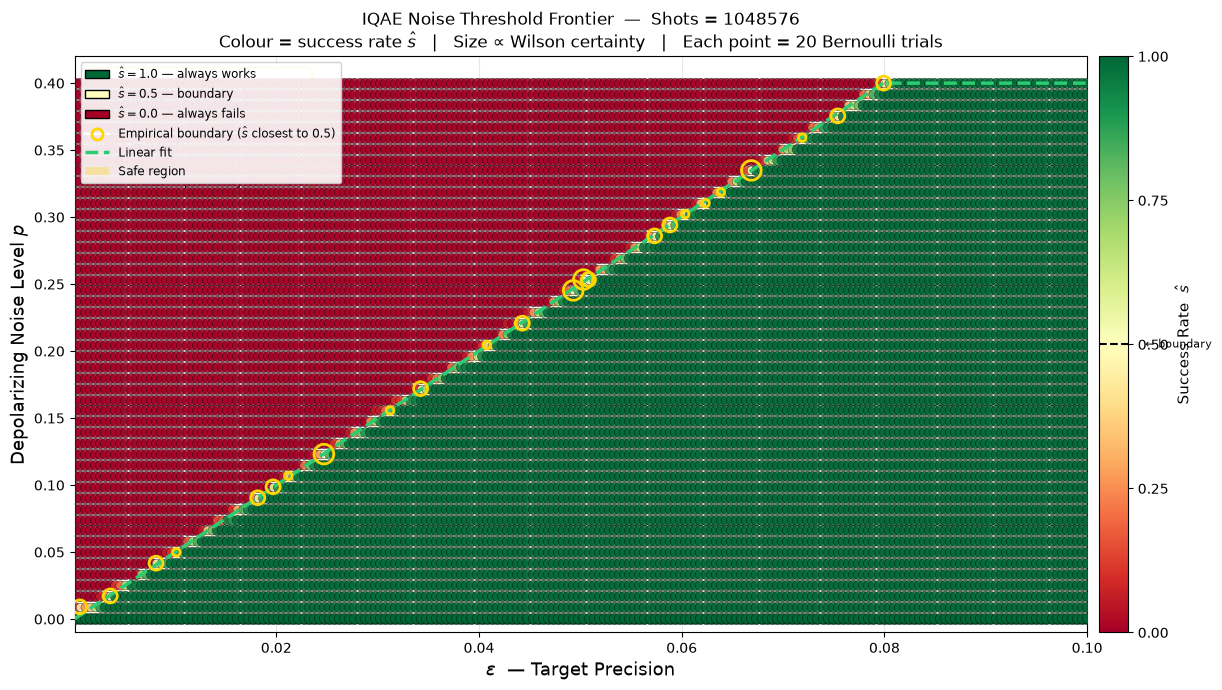


═══════════════════════════════════════════════════════════════════════════
  FULL SUMMARY — ALL SHOT COUNTS  |  Linear: p*(ε) = m·ε + c
═══════════════════════════════════════════════════════════════════════════
     Shots        R²        RMSE           m         σ_m           c         σ_c
  ------------------------------------------------------------------------
   1048576    0.9998    0.001594    5.010171    0.015595   -0.000249    0.000777
═══════════════════════════════════════════════════════════════════════════


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

# ══════════════════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════
ACCEPTANCE_BAND = 0.1   # only use points where success_rate ∈ [0.30, 0.70]

# ══════════════════════════════════════════════════════════════════════════════
# EMPIRICAL BOUNDARY EXTRACTOR
#
#   For each unique epsilon:
#     1. Find the noise point whose success_rate is closest to 0.5
#     2. Only keep it if success_rate is within ACCEPTANCE_BAND of 0.5
#        → tail points where the boundary is above the grid ceiling
#          naturally fall outside the band and are simply not added
#     3. NO error bar — the Wilson hw is a success-rate quantity,
#        not a noise-level quantity, so it must not be plotted on y-axis
# ══════════════════════════════════════════════════════════════════════════════
def extract_empirical_boundary(sweep_results):
    """
    Returns arrays of (epsilon, noise_at_50pct, success_rate_at_50pct)
    Only includes epsilons where a noise level genuinely lands near 50%.
    """
    eps_boundary      = []
    pstar_boundary    = []
    srate_boundary    = []   # actual success rate at the chosen point

    unique_epsilons = sorted(set(e["epsilon"] for e in sweep_results))

    for eps in unique_epsilons:
        pts = [e for e in sweep_results if e["epsilon"] == eps]
        pts.sort(key=lambda x: x["noise"])

        distances = [abs(p["success_rate"] - 0.5) for p in pts]
        idx_best  = int(np.argmin(distances))
        best_pt   = pts[idx_best]

        # Naturally excludes tail points — no forced truncation needed ✅
        if distances[idx_best] > ACCEPTANCE_BAND:
            continue

        eps_boundary.append(eps)
        pstar_boundary.append(best_pt["noise"])
        srate_boundary.append(best_pt["success_rate"])

    n_total   = len(unique_epsilons)
    n_kept    = len(eps_boundary)
    n_dropped = n_total - n_kept
    print(f"  📍 Boundary points: {n_kept} kept, "
          f"{n_dropped} dropped (success rate not within "
          f"{ACCEPTANCE_BAND} of 0.5 (50%))")

    return (np.array(eps_boundary),
            np.array(pstar_boundary),
            np.array(srate_boundary))

# ══════════════════════════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot

def rmse_metric(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# LINEAR FIT
#
#   p*(ε) = m·ε + c
#
#   Weighted by how close each point's success_rate is to 0.5:
#     w_i = 1 / |s_i - 0.5 + δ|
#   Points exactly at 50% carry the most weight.
#
#   - m > 0  (noise tolerance increases with epsilon)
#   - c free (let the data decide the intercept)
# ══════════════════════════════════════════════════════════════════════════════
def linear_model(eps, m, c):
    return m * eps + c

def fit_linear(eps_boundary, pstar_boundary, srate_boundary):
    # Weight by proximity to 50% — closest to boundary = most informative
    weights   = 1.0 / (np.abs(srate_boundary - 0.5) + 0.01)
    fit_sigma = 1.0 / weights    # curve_fit takes sigma = 1/weight

    try:
        popt, pcov = curve_fit(
            linear_model,
            eps_boundary,
            pstar_boundary,
            p0     = [1.0,  0.0],
            bounds = ([0.0, -np.inf], [np.inf, np.inf]),
            sigma  = fit_sigma,
            maxfev = 20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = linear_model(eps_boundary, *popt)
        r2     = r_squared(pstar_boundary, y_pred)
        rm     = rmse_metric(pstar_boundary, y_pred)

        return {
            "popt" : popt,
            "perr" : perr,
            "r2"   : r2,
            "rmse" : rm,
        }

    except RuntimeError as exc:
        print(f"  ⚠ Linear fit failed: {exc}")
        return None

# ══════════════════════════════════════════════════════════════════════════════
# PLOT FOR ONE SHOT COUNT
# ══════════════════════════════════════════════════════════════════════════════
def plot_shot_results(n_shots, sweep_results, fit_result,
                      eps_boundary, pstar_boundary, srate_boundary):

    fig, ax = plt.subplots(figsize=(13, 7))

    noise_all  = np.array([e["noise"] for e in sweep_results])
    noise_ceil = noise_all.max()

    # ── Colormap: green (s=1) → red (s=0) ────────────────────────────────────
    cmap = cm.RdYlGn
    norm = mcolors.Normalize(vmin=0.0, vmax=1.0)

    # ── Scatter all (ε, noise) points ────────────────────────────────────────
    for entry in sweep_results:
        s     = entry["success_rate"]
        hw    = entry["wilson_hw"]
        color = cmap(norm(s))
        size  = np.clip(200 * (1.0 - 2 * hw), 20, 200)
        ax.scatter(
            entry["epsilon"], entry["noise"],
            color      = color,
            s          = size,
            zorder     = 5,
            edgecolors = 'black',
            linewidths = 0.3,
            alpha      = 0.85
        )

    # ── Colorbar ──────────────────────────────────────────────────────────────
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.01)
    cbar.set_label("Success Rate  $\\hat{s}$", fontsize=11)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])
    cbar.ax.axhline(0.5, color='black', linewidth=1.5, linestyle='--')
    cbar.ax.text(1.6, 0.5, '← boundary', va='center', fontsize=8)

    # ── Empirical boundary points — NO error bars (Wilson hw is not y-axis) ──
    #    Marker size encodes how close to 50% the point actually is:
    #    larger = closer to 50% = more reliable boundary estimate
    marker_sizes = 200 * (1.0 - np.abs(srate_boundary - 0.5) / ACCEPTANCE_BAND)
    marker_sizes = np.clip(marker_sizes, 30, 200)

    ax.scatter(
        eps_boundary, pstar_boundary,
        s           = marker_sizes,
        facecolors  = 'none',
        edgecolors  = 'gold',
        linewidths  = 2.0,
        zorder      = 13,
        label       = r'Empirical boundary ($\hat{s}$ closest to $0.5$)'
    )

    # ── Linear fit curve ──────────────────────────────────────────────────────
    eps_dense = np.linspace(min(epsilon_values), max(epsilon_values), 600)

    if fit_result is not None:
        m, c    = fit_result["popt"]
        me, ce  = fit_result["perr"]
        y_dense = np.clip(linear_model(eps_dense, m, c), 0, noise_ceil)

        ax.plot(
            eps_dense, y_dense,
            color     = '#2ecc71',
            linewidth = 2.5,
            linestyle = '--',
            zorder    = 12,
            label     = f"Linear fit  [R²={fit_result['r2']:.4f} | RMSE={fit_result['rmse']:.4f}]"
        )

        # ── Safe zone under linear fit ────────────────────────────────────────
        ax.fill_between(
            eps_dense, 0, y_dense,
            color='gold', alpha=0.10, zorder=4, label='Safe region'
        )

        # ── Stats annotation ──────────────────────────────────────────────────
        stats_text = (
            f"Linear Fit:  $p^*(\\varepsilon) = m\\varepsilon + c$\n"
            f"$m = {m:.4f} \\pm {me:.4f}$\n"
            f"$c = {c:.4f} \\pm {ce:.4f}$\n"
            f"$R^2 = {fit_result['r2']:.4f}$\n"
            f"$\\mathrm{{RMSE}} = {fit_result['rmse']:.4f}$\n"
            f"Acceptance band: $|\\hat{{s}} - 0.5| \\leq {ACCEPTANCE_BAND}$\n"
            f"Marker size ∝ proximity to $\\hat{{s}}=0.5$"
        )
        ax.text(
            0.02, 0.97, stats_text,
            transform         = ax.transAxes,
            fontsize          = 9,
            verticalalignment = 'top',
            bbox              = dict(boxstyle='round,pad=0.5', facecolor='white',
                                     edgecolor='gold', alpha=0.92)
        )

    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlim(min(epsilon_values), max(epsilon_values))
    ax.set_ylim(-0.01, noise_ceil + 0.02)
    ax.set_xlabel(r"$\varepsilon$  — Target Precision",  fontsize=13)
    ax.set_ylabel("Depolarizing Noise Level $p$",        fontsize=13)
    ax.set_title(
        f"IQAE Noise Threshold Frontier  —  Shots = {n_shots}\n"
        f"Colour = success rate $\\hat{{s}}$   |   "
        f"Size ∝ Wilson certainty   |   "
        f"Each point = {N_REPEATS} Bernoulli trials",
        fontsize=12
    )

    # ── Legend ────────────────────────────────────────────────────────────────
    base_legend = [
        mpatches.Patch(facecolor=cmap(1.0), edgecolor='black',
                       label='$\\hat{s}=1.0$ — always works'),
        mpatches.Patch(facecolor=cmap(0.5), edgecolor='black',
                       label='$\\hat{s}=0.5$ — boundary'),
        mpatches.Patch(facecolor=cmap(0.0), edgecolor='black',
                       label='$\\hat{s}=0.0$ — always fails'),
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor='none', markeredgecolor='gold',
                   markeredgewidth=2.0, markersize=8,
                   label=r'Empirical boundary ($\hat{s}$ closest to $0.5$)'),
        plt.Line2D([0], [0], color='#2ecc71', linewidth=2.5, linestyle='--',
                   label='Linear fit'),
        mpatches.Patch(facecolor='gold', alpha=0.3, edgecolor='none',
                       label='Safe region'),
    ]
    ax.legend(
        handles    = base_legend,
        fontsize   = 8.5,
        loc        = 'upper left',
        framealpha = 0.90,
    )
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE
# ══════════════════════════════════════════════════════════════════════════════
def print_summary_table(all_fit_results):
    print(f"\n{'═'*75}")
    print(f"  FULL SUMMARY — ALL SHOT COUNTS  |  Linear: p*(ε) = m·ε + c")
    print(f"{'═'*75}")
    print(f"  {'Shots':>8}  {'R²':>8}  {'RMSE':>10}  {'m':>10}  {'σ_m':>10}  {'c':>10}  {'σ_c':>10}")
    print(f"  {'-'*72}")

    for n_shots, res in all_fit_results.items():
        if res is None:
            print(f"  {n_shots:>8}  {'—':>8}  {'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}  {'—':>10}  ❌")
            continue
        m,  c  = res["popt"]
        me, ce = res["perr"]
        print(
            f"  {n_shots:>8}  "
            f"{res['r2']:>8.4f}  "
            f"{res['rmse']:>10.6f}  "
            f"{m:>10.6f}  "
            f"{me:>10.6f}  "
            f"{c:>10.6f}  "
            f"{ce:>10.6f}"
        )

    print(f"{'═'*75}")

# ══════════════════════════════════════════════════════════════════════════════
# ANALYSIS LOOP — consumes `all_sweep_results` from Cell 1
# ══════════════════════════════════════════════════════════════════════════════
all_fit_results = {}

for n_shots, sweep_results in all_sweep_results.items():

    print(f"\n{'▓'*75}")
    print(f"  📊  Analysing  —  SHOTS = {n_shots}")
    print(f"{'▓'*75}")

    eps_boundary, pstar_boundary, srate_boundary = extract_empirical_boundary(sweep_results)

    fit_result = fit_linear(eps_boundary, pstar_boundary, srate_boundary)

    all_fit_results[n_shots] = fit_result

    plot_shot_results(n_shots, sweep_results, fit_result,
                      eps_boundary, pstar_boundary, srate_boundary)

print_summary_table(all_fit_results)